# 01 — Phân tích khám phá dữ liệu (EDA): VN30 theo 7 nhóm ngành

**Đồ án Tối ưu hóa & Ứng dụng — UIT**

Mục tiêu của notebook:
1. **Kiểm tra chất lượng dữ liệu** thô (yfinance) và làm sạch có kiểm soát — file gốc trong `data/` được giữ nguyên, dữ liệu sạch ghi ra `data/processed/`.
2. **Mô tả thống kê** 7 chỉ số ngành (equal-weighted) được gom từ 30 mã VN30.
3. Rút ra các **đặc điểm dữ liệu có hệ quả trực tiếp tới việc chọn mô hình tối ưu** (phân phối đuôi dày → CVaR, tương quan cao/phân cấp → HRP, sai số ước lượng $\mu$ lớn → Black-Litterman, mục tiêu không lồi → NSGA-III / MAP-Elites).

| Mục | Nội dung |
|---|---|
| 1 | Tổng quan dữ liệu |
| 2 | Chất lượng dữ liệu & làm sạch |
| 3 | Thống kê mô tả |
| 4 | Hiệu suất tích lũy & drawdown |
| 5 | Lợi nhuận theo năm |
| 6 | Phân phối lợi nhuận & kiểm định chuẩn |
| 7 | Cụm biến động (volatility clustering) |
| 8 | Cấu trúc tương quan |
| 9 | PCA & độ ổn định ma trận hiệp phương sai |
| 10 | Bản đồ rủi ro – lợi nhuận |
| 11 | Sai số ước lượng lợi nhuận kỳ vọng |
| 12 | Tổng kết & hàm ý cho mô hình |

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf

from scripts import data_utils as du, metrics as M, viz
from scripts.hrp import correlation_distance

viz.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

RF = 0.03      # lãi suất phi rủi ro năm (~ lợi suất TPCP Việt Nam kỳ hạn 10 năm)
ALPHA = 0.95   # mức tin cậy cho VaR / CVaR
SECTORS = du.SECTOR_ORDER
VI = du.SECTOR_VI
SEC_COLORS = dict(zip(SECTORS, viz.CATEGORICAL))

## 1. Tổng quan dữ liệu

Dữ liệu giá đóng cửa (đã điều chỉnh theo yfinance) của 30 mã VN30, khoảng 5 năm. Notebook `crawl_group_vn30.ipynb` đã gom 30 mã thành 7 nhóm ngành theo ICB bằng trung bình cộng return (equal-weighted):

$$R_{k,t} = \frac{1}{|S_k|}\sum_{i\in S_k} R_{i,t}$$

In [2]:
raw = du.load_raw()
prices, ret_raw, mapping = raw["prices"], raw["returns"], raw["mapping"]

overview = pd.DataFrame({
    name: {"Số dòng": df.shape[0], "Số cột": df.shape[1],
           "Từ ngày": df.index.min().date() if isinstance(df.index, pd.DatetimeIndex) else "",
           "Đến ngày": df.index.max().date() if isinstance(df.index, pd.DatetimeIndex) else ""}
    for name, df in raw.items()
}).T
display(overview)

sector_table = (mapping.groupby("Sector")["Ticker"].agg(["count", lambda s: ", ".join(s)])
                .reindex(SECTORS).rename(columns={"count": "Số mã", "<lambda_0>": "Mã cổ phiếu"}))
sector_table.index = [VI[s] for s in sector_table.index]
display(sector_table)

,Số dòng,Số cột,Từ ngày,Đến ngày
prices,1294,30,2021-10-13,2026-10-09
returns,1293,30,2021-10-14,2026-10-09
sector_prices,1293,7,2021-10-14,2026-10-09
sector_returns,1293,7,2021-10-14,2026-10-09
mapping,30,2,,


,Số mã,Mã cổ phiếu
Ngân hàng,13,"ACB, BID, CTG, HDB, MBB, SHB, SSB, STB, TCB, T..."
Bất động sản,4,"BCM, VHM, VIC, VRE"
Tiêu dùng & Bán lẻ,4,"MWG, MSN, SAB, VNM"
Năng lượng & Tiện ích,3,"GAS, PLX, POW"
Thép & Vật liệu,2,"HPG, GVR"
Công nghệ,1,FPT
Dịch vụ tài chính,3,"SSI, BVH, VJC"


Nhóm **Ngân hàng chiếm 13/30 mã** (43%) — đặc trưng của VN30. Nhóm **Công nghệ chỉ có 1 mã (FPT)**, nên "chỉ số ngành" này thực chất mang toàn bộ rủi ro riêng của một doanh nghiệp. Đây là điểm cần nhớ khi diễn giải tỷ trọng tối ưu.

## 2. Chất lượng dữ liệu & làm sạch

### 2.1 Giá trị thiếu, trùng lặp, khoảng cách giữa các phiên

In [3]:
qc = pd.Series({
    "Giá trị NaN (returns)": int(ret_raw.isna().sum().sum()),
    "Ngày trùng lặp": int(ret_raw.index.duplicated().sum()),
    "Giá <= 0": int((prices <= 0).sum().sum()),
}, name="Số lượng")
display(qc.to_frame())

gap = ret_raw.index.to_series().diff().dt.days.dropna().astype(int)
gap_tbl = gap.value_counts().sort_index().rename("Số lần").to_frame()
gap_tbl.index.name = "Khoảng cách (ngày lịch)"
display(gap_tbl.T)

,Số lượng
Giá trị NaN (returns),0
Ngày trùng lặp,0
Giá <= 0,0


Khoảng cách (ngày lịch),1,2,3,4,5,6
Số lần,1029,3,257,1,1,1


Không có NaN hay ngày trùng — vì notebook crawl đã `dropna()` trên toàn bộ 30 mã. Khoảng cách 3 ngày là cuối tuần; các khoảng 2, 4, 5, 6 ngày cho thấy có phiên bị loại (vì 1 mã thiếu dữ liệu thì cả phiên bị bỏ). Khi đó return được tính **gộp nhiều phiên** — cần nhớ khi kiểm tra biên độ giá.

### 2.2 Phiên nghỉ lễ bị forward-fill

Nếu **cả 30 mã** cùng có return đúng bằng 0 trong một phiên, gần như chắc chắn đó không phải giao dịch thật mà là ngày nghỉ được nguồn dữ liệu lấp bằng giá phiên trước.

In [4]:
hol = du.holiday_rows(ret_raw)
hol_dates = ret_raw.index[hol]
print(f"Số phiên mà cả 30 mã có return = 0: {hol.sum()} / {len(ret_raw)} ({hol.mean():.1%})")

by_year = (pd.Series(hol_dates.strftime("%d/%m"), index=hol_dates.year)
           .groupby(level=0).agg(lambda s: ", ".join(s)))
display(by_year.rename("Các ngày (dd/mm)").to_frame())

# Xác suất 30 mã cùng đứng giá một cách tự nhiên là cực nhỏ: kiểm tra tỷ lệ 0 của từng mã ở các phiên còn lại
p_zero = (ret_raw.loc[~hol] == 0).mean()
print(f"Tỷ lệ phiên đứng giá trung bình của 1 mã (ngoài các ngày trên): {p_zero.mean():.1%}"
      f"  ->  xác suất 30 mã cùng đứng giá nếu độc lập ~ {np.prod(p_zero):.1e}")

Số phiên mà cả 30 mã có return = 0: 87 / 1293 (6.7%)


,Các ngày (dd/mm)
Date,
2021,"14/10, 18/10, 25/10, 01/11"
2022,"03/01, 31/01, 01/02, 02/02, 03/02, 04/02, 15/0..."
2023,"02/01, 20/01, 23/01, 24/01, 25/01, 26/01, 01/0..."
2024,"01/01, 25/01, 02/02, 08/02, 09/02, 29/04, 30/0..."
2025,"16/01, 27/01, 28/01, 29/01, 30/01, 31/01, 30/0..."
2026,"01/01, 02/01, 16/02, 17/02, 18/02, 19/02, 20/0..."


Tỷ lệ phiên đứng giá trung bình của 1 mã (ngoài các ngày trên): 8.9%  ->  xác suất 30 mã cùng đứng giá nếu độc lập ~ 7.1e-33


Các ngày rơi đúng vào **Tết Nguyên đán** (cuối tháng 1 – tháng 2), **30/4 – 1/5**, **2/9**, **Giỗ Tổ** và **1/1**. Giữ lại các dòng này sẽ:
- làm **giảm độ biến động** ước lượng (thêm các quan sát 0 giả),
- làm sai **hệ số năm hóa**: sau khi loại bỏ, mẫu còn ~242 phiên/năm thay vì 252.

→ **Loại bỏ** toàn bộ các dòng này (không ảnh hưởng tới lợi nhuận tích lũy vì return = 0).

### 2.3 Vi phạm biên độ giá HOSE (±7%)

Trên HOSE, giá một phiên chỉ được dao động tối đa ±7% so với giá tham chiếu. Return vượt ngưỡng chỉ hợp lý khi return đó **gộp nhiều phiên** (do phiên bị loại ở bước crawl). Ngược lại, đó là dấu hiệu giá chưa được điều chỉnh khi doanh nghiệp **chia tách / trả cổ tức bằng cổ phiếu**, hoặc lỗi dữ liệu.

In [5]:
r_nh = ret_raw.loc[~hol]
prev = r_nh.index.to_series().shift(1)
n_sessions = pd.Series(np.busday_count(prev.values[1:].astype("datetime64[D]"),
                                       r_nh.index.values[1:].astype("datetime64[D]")), index=r_nh.index[1:])
st = r_nh.stack()
big = st[st.abs() > du.HOSE_BAND + 0.005].rename("Return").reset_index()
big.columns = ["Date", "Ticker", "Return"]
big["Số ngày làm việc gộp"] = big["Date"].map(n_sessions).fillna(1).astype(int)
big["Giải thích được bởi gộp phiên?"] = big["Return"].abs() <= (1.07 ** big["Số ngày làm việc gộp"] - 1)
print(f"Số quan sát |r| > 7.5%: {len(big)} trên {st.size:,} quan sát mã-phiên")
display(big.groupby("Giải thích được bởi gộp phiên?").size().rename("Số quan sát").to_frame())
unexplained = big.loc[~big["Giải thích được bởi gộp phiên?"]].sort_values("Return", key=abs, ascending=False)
n_same_day = big.groupby("Date")["Ticker"].transform("size")
market_wide = (n_same_day >= 3) & ~big["Giải thích được bởi gộp phiên?"]
print(f"Trong {(~big['Giải thích được bởi gộp phiên?']).sum()} quan sát không giải thích được bằng gộp phiên: "
      f"{market_wide.sum()} rơi vào phiên có >= 3 mã cùng vượt biên độ (biến động toàn thị trường), "
      f"{(big['Return'].abs() > 0.15).sum()} quan sát có |r| > 15%.")
print("15 quan sát lớn nhất KHÔNG giải thích được bằng gộp phiên:")
display(viz.fmt(unexplained.head(15), pct=("Return",)))

Số quan sát |r| > 7.5%: 82 trên 36,180 quan sát mã-phiên


,Số quan sát
Giải thích được bởi gộp phiên?,
False,72
True,10


Trong 72 quan sát không giải thích được bằng gộp phiên: 41 rơi vào phiên có >= 3 mã cùng vượt biên độ (biến động toàn thị trường), 9 quan sát có |r| > 15%.
15 quan sát lớn nhất KHÔNG giải thích được bằng gộp phiên:


,Date,Ticker,Return,Số ngày làm việc gộp,Giải thích được bởi gộp phiên?
12,2024-06-11,TCB,-49.54%,1,Không
81,2026-10-09,HDB,45.00%,1,Không
13,2025-03-03,VCB,-33.11%,1,Không
72,2025-12-18,HDB,29.69%,1,Không
9,2023-05-29,HDB,20.80%,1,Không
16,2025-05-23,ACB,19.93%,1,Không
73,2025-12-19,HDB,-19.16%,1,Không
17,2025-05-26,ACB,-15.85%,1,Không
1,2021-10-28,BCM,15.49%,1,Không
49,2025-10-13,VIC,14.43%,1,Không


Phần lớn các quan sát vượt ±7% **không** giải thích được bằng việc gộp phiên. Đây là hạn chế đã biết của yfinance với thị trường Việt Nam: giá tham chiếu và giá đóng cửa đôi khi bị lệch ngày, đặc biệt ở các phiên cả thị trường biến động mạnh (vd. 25/08/2025, 20/10/2025, khi hàng loạt mã cùng giảm sàn). 63/72 quan sát này có |r| ≤ 15%, và 41/72 rơi vào phiên có từ 3 mã trở lên cùng vượt biên độ, tức **đi cùng chiều với thị trường chung**, nên vẫn mang thông tin rủi ro thật. Vì vậy mình **giữ lại** chúng và chỉ sửa những điểm có bằng chứng rõ ràng là lỗi:

- **Spike-reversal**: $|r_t|>10\%$ và $|r_{t+1}|>10\%$ trái dấu → lỗi giá 1 phiên. Gộp thành một return ròng $(1+r_t)(1+r_{t+1})-1$ tại phiên $t+1$, phiên $t$ đặt bằng 0 (bảo toàn giá trị tích lũy thực).
- **Corporate action**: $|r_t| > 20\%$ (vượt xa mức gộp 2 phiên trần/sàn) → sự kiện chia tách/cổ tức cổ phiếu chưa điều chỉnh. Đặt bằng 0.

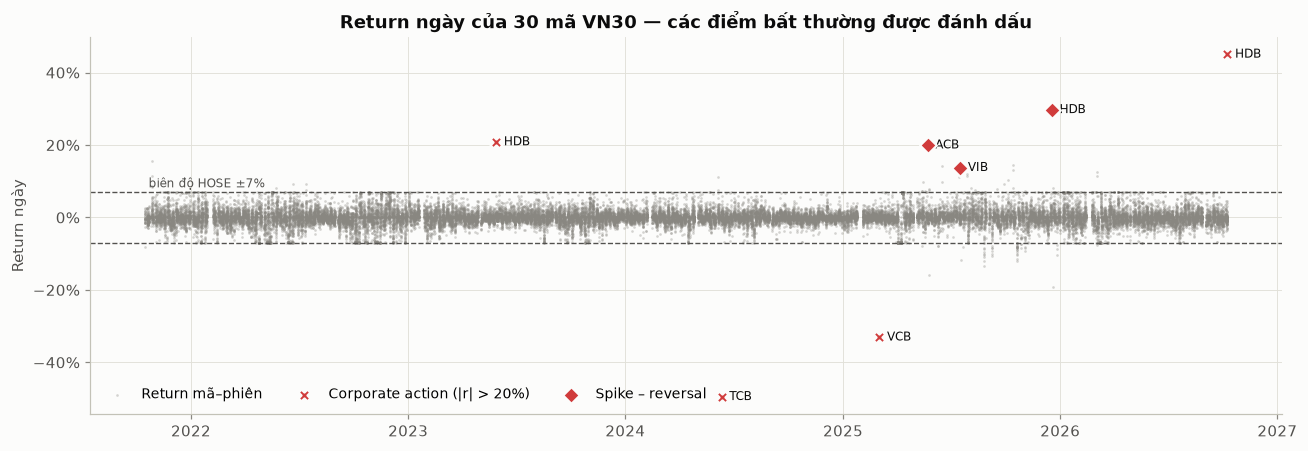

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.2))
xs = st.index.get_level_values(0)
ax.scatter(xs, st.values, s=3, color=viz.MUTED, alpha=0.35, linewidths=0, label="Return mã–phiên")
ax.axhline(0.07, color=viz.INK2, lw=0.9, ls="--"); ax.axhline(-0.07, color=viz.INK2, lw=0.9, ls="--")
ax.text(xs.min(), 0.075, " biên độ HOSE ±7%", color=viz.INK2, fontsize=8, va="bottom")
ret_clean, clean_log, n_hol = du.clean_returns(ret_raw)
for typ, mk, lab in [("corporate_action", "X", "Corporate action (|r| > 20%)"), ("spike_reversal", "D", "Spike – reversal")]:
    sub = clean_log[clean_log.Type == typ]
    ax.scatter(sub.Date, sub.Return, marker=mk, s=60, color="#d03b3b", edgecolor=viz.SURFACE, linewidth=1.5, zorder=5, label=lab)
    for _, r in sub.iterrows():
        ax.annotate(r.Ticker, (r.Date, r.Return), xytext=(5, 0), textcoords="offset points", fontsize=8, color=viz.INK, va="center")
viz.pct_axis(ax)
ax.set_title("Return ngày của 30 mã VN30 — các điểm bất thường được đánh dấu")
ax.set_ylabel("Return ngày")
ax.legend(loc="lower left", ncol=3, markerscale=1)
plt.tight_layout(); plt.show()

### 2.4 Kết quả làm sạch

Đã loại 87 phiên nghỉ lễ  ->  còn 1206 phiên.  Sửa 7 điểm bất thường:


,Date,Ticker,Return,NextReturn,Type,Fixed
0,2023-05-29,HDB,20.80%,0.00%,corporate_action,0.00%
1,2024-06-11,TCB,-49.54%,0.10%,corporate_action,0.00%
2,2025-03-03,VCB,-33.11%,-0.32%,corporate_action,0.00%
3,2025-05-23,ACB,19.93%,-15.85%,spike_reversal,0.92%
4,2025-07-17,VIB,13.71%,-11.66%,spike_reversal,0.45%
5,2025-12-18,HDB,29.69%,-19.16%,spike_reversal,4.84%
6,2026-10-09,HDB,45.00%,,corporate_action,0.00%


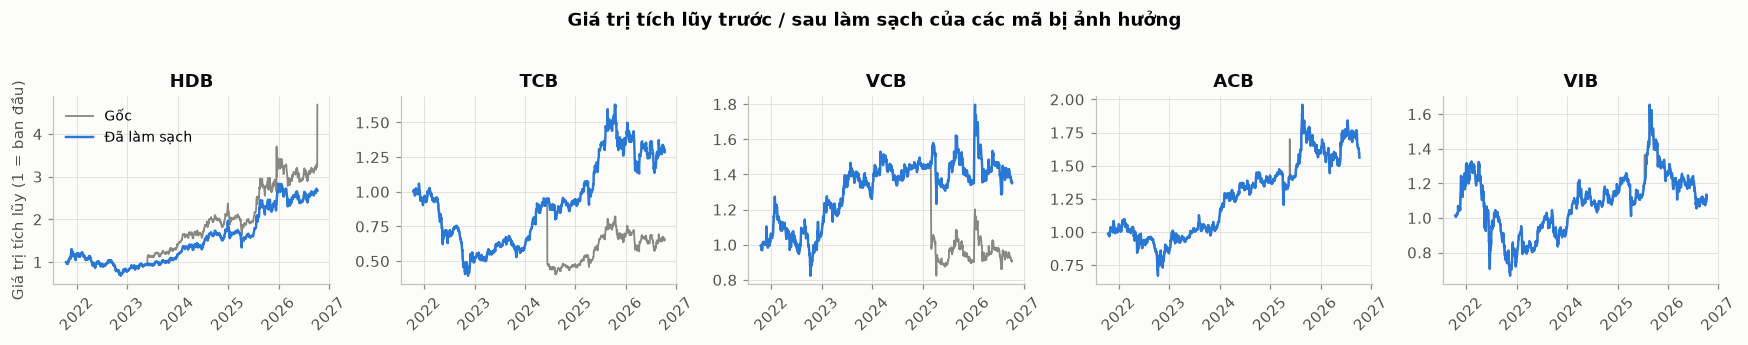

In [7]:
print(f"Đã loại {n_hol} phiên nghỉ lễ  ->  còn {len(ret_clean)} phiên.  Sửa {len(clean_log)} điểm bất thường:")
log_show = clean_log.copy()
log_show["Date"] = log_show["Date"].dt.date
display(viz.fmt(log_show, pct=("Return", "NextReturn", "Fixed")))

affected = clean_log.Ticker.unique()
fig, axes = plt.subplots(1, len(affected), figsize=(3.2 * len(affected), 3), sharey=False)
for ax, tic in zip(np.atleast_1d(axes), affected):
    raw_w = (1 + r_nh[tic]).cumprod()
    cln_w = (1 + ret_clean[tic]).cumprod()
    ax.plot(raw_w.index, raw_w, color=viz.MUTED, lw=1.2, label="Gốc")
    ax.plot(cln_w.index, cln_w, color=viz.CATEGORICAL[0], lw=1.6, label="Đã làm sạch")
    ax.set_title(tic); ax.tick_params(axis="x", rotation=45)
np.atleast_1d(axes)[0].set_ylabel("Giá trị tích lũy (1 = ban đầu)")
np.atleast_1d(axes)[0].legend(loc="upper left")
fig.suptitle("Giá trị tích lũy trước / sau làm sạch của các mã bị ảnh hưởng", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

Ví dụ **TCB** (06/2024, chia thưởng tỷ lệ 1:1) và **VCB** (03/2025, cổ tức cổ phiếu): dữ liệu gốc ghi nhận như một cú sập −50% / −33%, trong khi nhà đầu tư thực tế không mất tiền. Nếu không sửa, các mô hình sẽ đánh giá sai lệch nghiêm trọng rủi ro đuôi (CVaR, MDD) của nhóm Ngân hàng.

### 2.5 Xây dựng lại chỉ số ngành từ dữ liệu sạch

In [8]:
sec = du.build_sector_returns(ret_clean, mapping)
du.save_processed(ret_clean, sec, clean_log)
PPY = du.periods_per_year(sec.index)
print(f"Số phiên/năm thực tế: {PPY:.1f}   |   Giai đoạn: {sec.index[0].date()} -> {sec.index[-1].date()}   |   {len(sec)} phiên")

old = raw["sector_returns"]
cmp_ = pd.DataFrame({
    "μ năm — dữ liệu gốc (×252)": old.mean() * 252,
    "μ năm — dữ liệu sạch (×PPY)": sec.mean() * PPY,
    "σ năm — dữ liệu gốc (×√252)": old.std() * np.sqrt(252),
    "σ năm — dữ liệu sạch (×√PPY)": sec.std() * np.sqrt(PPY),
    "MaxDD — gốc": [M.max_drawdown(old[c]) for c in SECTORS],
    "MaxDD — sạch": [M.max_drawdown(sec[c]) for c in SECTORS],
}).rename(index=VI)
display(viz.fmt(cmp_, pct=cmp_.columns))
print("Đã lưu: data/processed/VN30_Returns_clean.csv, VN30_Sectors_Returns_clean.csv, cleaning_log.csv")

Số phiên/năm thực tế: 242.0   |   Giai đoạn: 2021-10-15 -> 2026-10-09   |   1206 phiên


,μ năm — dữ liệu gốc (×252),μ năm — dữ liệu sạch (×PPY),σ năm — dữ liệu gốc (×√252),σ năm — dữ liệu sạch (×√PPY),MaxDD — gốc,MaxDD — sạch
Ngân hàng,11.36%,11.80%,23.14%,23.28%,42.82%,42.82%
Bất động sản,15.70%,16.16%,28.26%,28.68%,45.35%,45.35%
Tiêu dùng & Bán lẻ,0.63%,0.65%,21.24%,21.55%,39.27%,39.27%
Năng lượng & Tiện ích,6.53%,6.72%,28.27%,28.68%,40.69%,40.69%
Thép & Vật liệu,3.14%,3.23%,32.60%,33.08%,72.46%,72.46%
Công nghệ,8.73%,8.99%,27.72%,28.13%,52.10%,52.10%
Dịch vụ tài chính,9.90%,10.20%,24.84%,25.21%,44.13%,44.13%


Đã lưu: data/processed/VN30_Returns_clean.csv, VN30_Sectors_Returns_clean.csv, cleaning_log.csv


## 3. Thống kê mô tả

Ngoài 7 ngành, ta thêm 2 danh mục tham chiếu dùng xuyên suốt đồ án:
- **VN30-EW**: chia đều 30 mã (≈ đại diện thị trường; tương đương tỷ trọng ngành theo số mã).
- **1/N (7 ngành)**: chia đều 7 ngành — benchmark "ngây thơ" nổi tiếng khó đánh bại (DeMiguel et al., 2009).

Các chỉ số: CAGR (lợi nhuận kép năm), Volatility năm, Sharpe & Sortino (rf = 3%), Max Drawdown, Calmar = CAGR/MaxDD, VaR/CVaR lịch sử 95% theo ngày, Skewness, Excess Kurtosis.

In [9]:
vn30ew = ret_clean.mean(axis=1).rename("VN30-EW")
ew7 = sec.mean(axis=1).rename("1/N (7 ngành)")
assets = pd.concat([sec, vn30ew, ew7], axis=1)
summ = M.summary(assets, RF, PPY, ALPHA).rename(index=VI)
display(viz.fmt(summ, pct=("CAGR", "Volatility", "MaxDD", "VaR95", "CVaR95")))

,CAGR,Volatility,Sharpe,Sortino,MaxDD,Calmar,VaR95,CVaR95,Skew,Kurtosis
Ngân hàng,9.50%,23.28%,0.380,0.518,42.82%,0.222,2.37%,3.92%,-0.607,4.733
Bất động sản,12.80%,28.68%,0.461,0.664,45.35%,0.282,3.07%,4.38%,-0.103,2.319
Tiêu dùng & Bán lẻ,-1.66%,21.55%,-0.107,-0.146,39.27%,-0.042,2.26%,3.42%,-0.282,3.178
Năng lượng & Tiện ích,2.64%,28.68%,0.131,0.187,40.69%,0.065,3.05%,4.57%,0.013,2.828
Thép & Vật liệu,-2.24%,33.08%,0.008,0.011,72.46%,-0.031,3.77%,5.42%,-0.374,1.654
Công nghệ,5.18%,28.13%,0.215,0.315,52.10%,0.099,2.80%,4.11%,0.178,2.717
Dịch vụ tài chính,7.27%,25.21%,0.287,0.408,44.13%,0.165,2.72%,3.97%,-0.166,2.324
VN30-EW,7.71%,20.61%,0.321,0.428,37.43%,0.206,2.08%,3.55%,-0.725,4.852
1/N (7 ngành),6.24%,20.90%,0.253,0.340,38.32%,0.163,2.11%,3.53%,-0.607,4.240


## 4. Hiệu suất tích lũy & drawdown

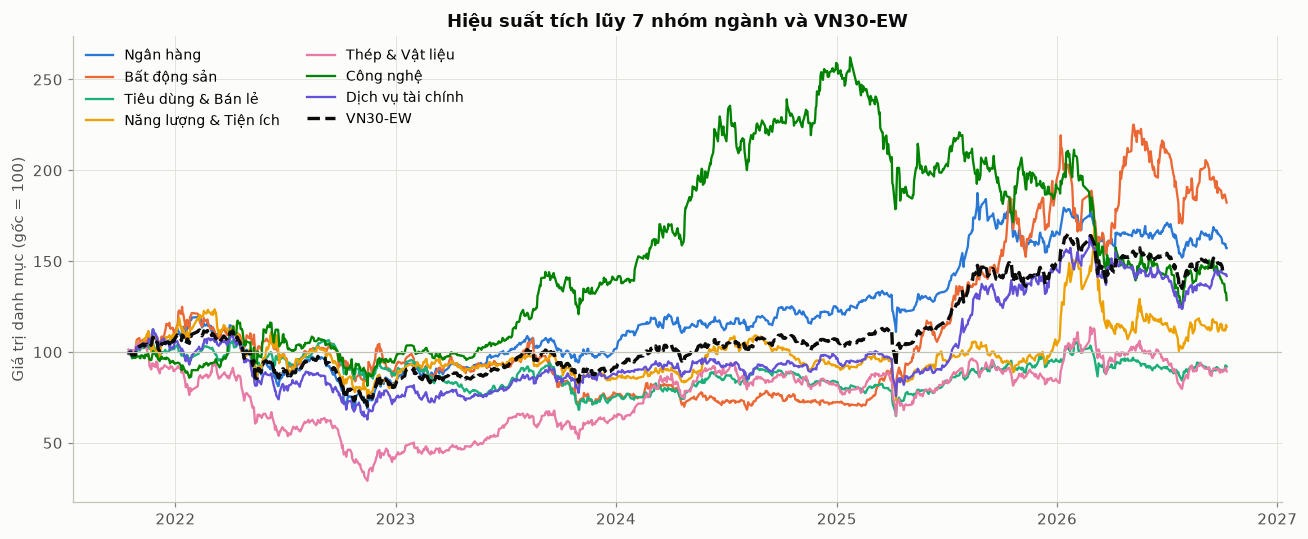

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
wealth = (1 + assets).cumprod() * 100
for s in SECTORS:
    ax.plot(wealth.index, wealth[s], color=SEC_COLORS[s], lw=1.5, label=VI[s])
ax.plot(wealth.index, wealth["VN30-EW"], color=viz.INK, lw=2.2, ls="--", label="VN30-EW")
ax.axhline(100, color=viz.AXIS, lw=0.8)
ax.set_ylabel("Giá trị danh mục (gốc = 100)")
ax.set_title("Hiệu suất tích lũy 7 nhóm ngành và VN30-EW")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

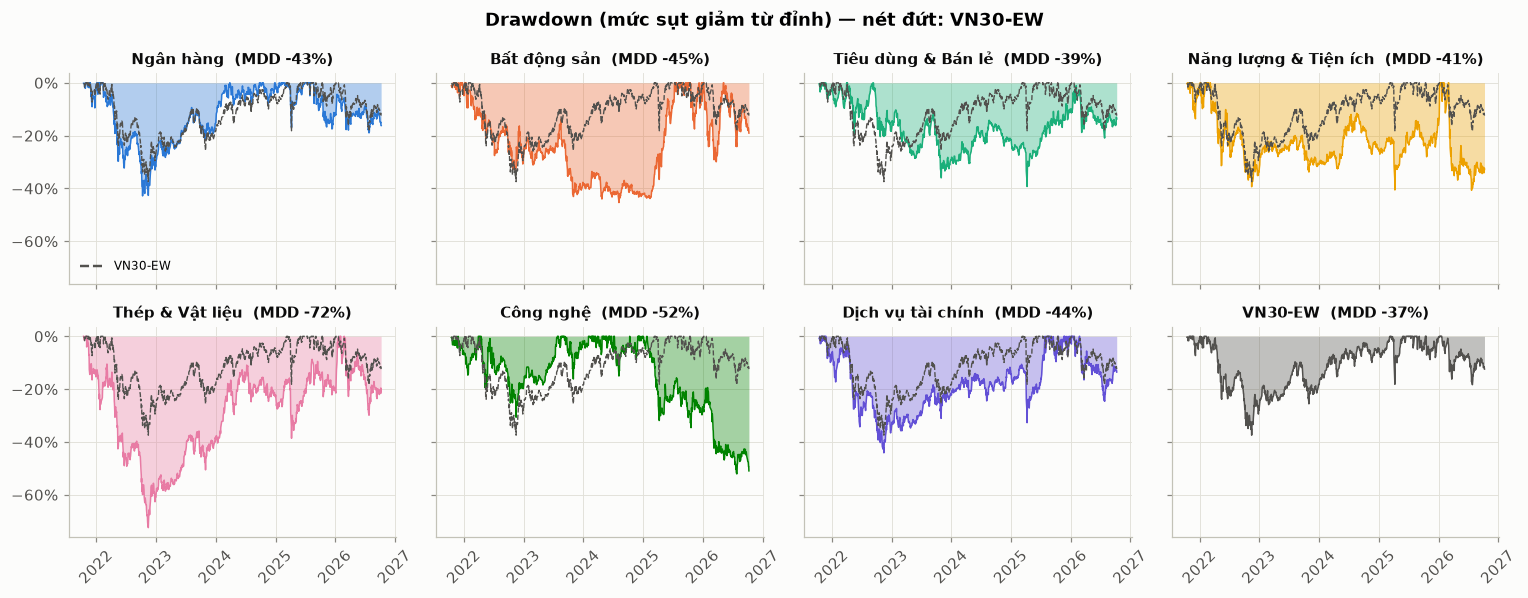

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharex=True, sharey=True)
dd_mkt = M.drawdown(vn30ew.values)
for ax, name in zip(axes.ravel(), SECTORS + ["VN30-EW"]):
    dd = M.drawdown(assets[name].values)
    col = SEC_COLORS.get(name, viz.INK2)
    ax.fill_between(assets.index, dd, 0, color=col, alpha=0.35, linewidth=0)
    ax.plot(assets.index, dd, color=col, lw=1.0)
    if name != "VN30-EW":
        ax.plot(assets.index, dd_mkt, color=viz.INK2, lw=0.9, ls="--")
    ax.set_title(f"{VI.get(name, name)}  (MDD {dd.min():.0%})", fontsize=10)
    viz.pct_axis(ax); ax.tick_params(axis="x", rotation=45)
axes[0, 0].plot([], [], color=viz.INK2, ls="--", label="VN30-EW"); axes[0, 0].legend(loc="lower left", fontsize=8)
fig.suptitle("Drawdown (mức sụt giảm từ đỉnh) — nét đứt: VN30-EW", fontweight="bold")
plt.tight_layout(); plt.show()

- **2022** là thị trường giá xuống sâu (khủng hoảng trái phiếu doanh nghiệp, siết tín dụng BĐS): mọi ngành cùng giảm. Thép & Vật liệu mất tới 72% từ đỉnh; VN30-EW mất 37%.
- Các drawdown lớn nhất **không xảy ra cùng lúc**: Bất động sản chìm sâu kéo dài 2022 → giữa 2025 (rồi tăng +169% trong năm 2025), trong khi Công nghệ (FPT) đạt đỉnh đầu 2025 rồi sụt hơn 50%. Sự lệch pha này là **nguồn gốc của lợi ích đa dạng hóa**: MDD của VN30-EW (37%) thấp hơn MDD của mọi ngành đơn lẻ.

## 5. Lợi nhuận theo năm

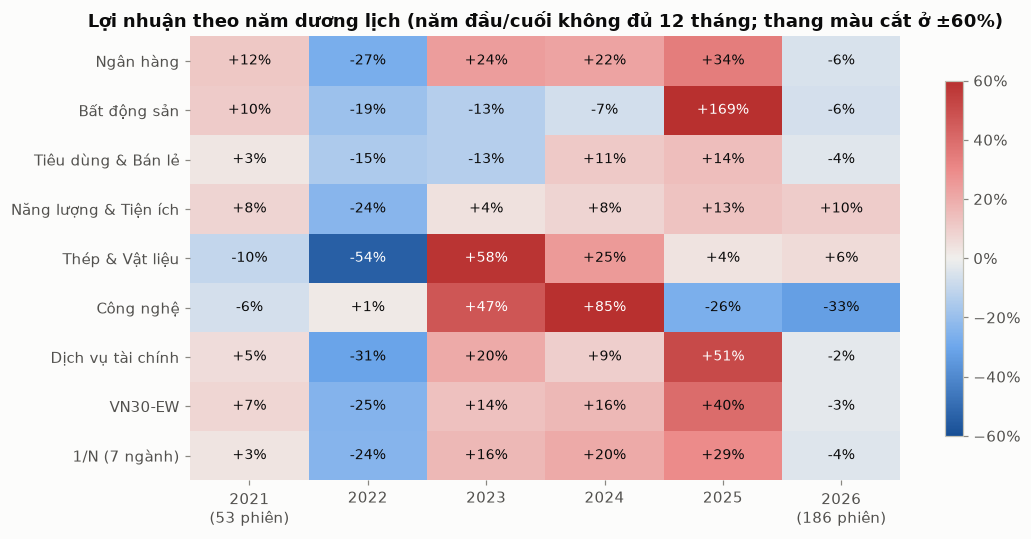

In [12]:
yearly = (1 + assets).groupby(assets.index.year).prod() - 1
counts = assets.groupby(assets.index.year).size()
yearly.index = [f"{y}" + (f"\n({n} phiên)" if n < 200 else "") for y, n in counts.items()]
Y = yearly.T.rename(index=VI)

fig, ax = plt.subplots(figsize=(10, 5))
lim = 0.6  # cắt thang màu ở ±60% để ô +169% không lấn át các ô còn lại
im = ax.imshow(Y.values, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
for i in range(Y.shape[0]):
    for j in range(Y.shape[1]):
        v = Y.values[i, j]
        ax.text(j, i, f"{v:+.0%}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.7 * lim else viz.INK)
ax.set_xticks(range(Y.shape[1]), Y.columns); ax.set_yticks(range(Y.shape[0]), Y.index)
ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Lợi nhuận theo năm dương lịch (năm đầu/cuối không đủ 12 tháng; thang màu cắt ở ±60%)")
plt.colorbar(im, ax=ax, format=plt.matplotlib.ticker.PercentFormatter(1.0), shrink=0.8)
plt.tight_layout(); plt.show()

**Thứ hạng ngành thay đổi mạnh qua từng năm** (ngành tốt nhất năm này thường không còn đứng đầu năm sau). Đây là bằng chứng trực quan cho việc lợi nhuận kỳ vọng $\mu$ rất khó dự báo — điểm yếu chí mạng của Markowitz (mục 11).

## 6. Phân phối lợi nhuận & kiểm định chuẩn

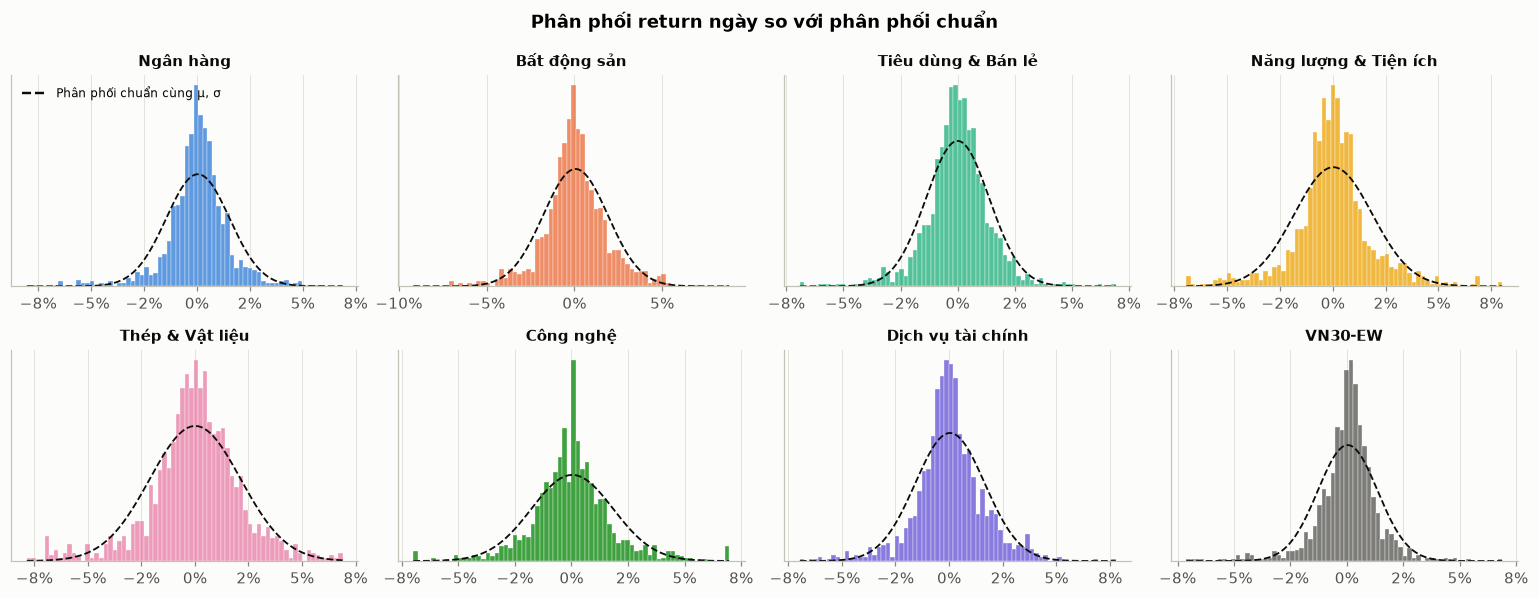

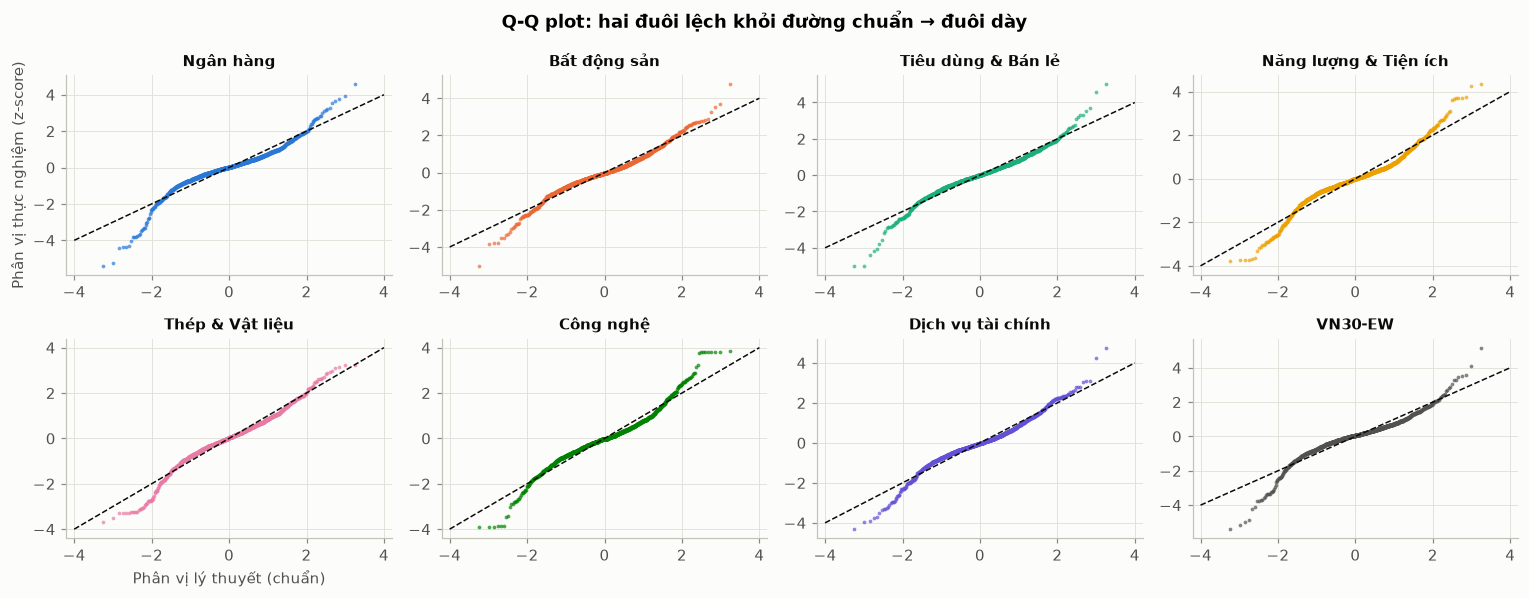

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, name in zip(axes.ravel(), SECTORS + ["VN30-EW"]):
    r = assets[name].values
    col = SEC_COLORS.get(name, viz.INK2)
    ax.hist(r, bins=70, density=True, color=col, alpha=0.75, edgecolor=viz.SURFACE, linewidth=0.3)
    x = np.linspace(r.min(), r.max(), 300)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), color=viz.INK, lw=1.2, ls="--")
    ax.set_title(VI.get(name, name), fontsize=10)
    viz.pct_axis(ax, "x"); ax.set_yticks([])
axes[0, 0].plot([], [], color=viz.INK, ls="--", label="Phân phối chuẩn cùng μ, σ"); axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Phân phối return ngày so với phân phối chuẩn", fontweight="bold")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, name in zip(axes.ravel(), SECTORS + ["VN30-EW"]):
    z = (assets[name] - assets[name].mean()) / assets[name].std()
    (osm, osr), _ = stats.probplot(z, dist="norm")
    ax.scatter(osm, osr, s=6, color=SEC_COLORS.get(name, viz.INK2), alpha=0.7, linewidths=0)
    ax.plot([-4, 4], [-4, 4], color=viz.INK, lw=1, ls="--")
    ax.set_title(VI.get(name, name), fontsize=10)
    ax.set_xlim(-4.2, 4.2)
axes[1, 0].set_xlabel("Phân vị lý thuyết (chuẩn)"); axes[0, 0].set_ylabel("Phân vị thực nghiệm (z-score)")
fig.suptitle("Q-Q plot: hai đuôi lệch khỏi đường chuẩn → đuôi dày", fontweight="bold")
plt.tight_layout(); plt.show()

In [14]:
rows = {}
for name in assets.columns:
    r = assets[name].values
    z = (r - r.mean()) / r.std()
    jb, p = stats.jarque_bera(r)
    rows[VI.get(name, name)] = {
        "Skew": stats.skew(r), "Excess kurtosis": stats.kurtosis(r),
        "Jarque-Bera": jb, "p-value": p,
        "% phiên |z|>3 (thực tế)": np.mean(np.abs(z) > 3),
        "% phiên |z|>3 (nếu chuẩn)": 2 * stats.norm.sf(3),
        "CVaR95 thực / CVaR95 chuẩn": M.var_cvar(r, ALPHA)[1] / (-(r.mean()) + r.std() * stats.norm.pdf(stats.norm.ppf(ALPHA)) / (1 - ALPHA)),
    }
norm_tbl = pd.DataFrame(rows).T
display(viz.fmt(norm_tbl, pct=("% phiên |z|>3 (thực tế)", "% phiên |z|>3 (nếu chuẩn)"), dec=3))

,Skew,Excess kurtosis,Jarque-Bera,p-value,% phiên |z|>3 (thực tế),% phiên |z|>3 (nếu chuẩn),CVaR95 thực / CVaR95 chuẩn
Ngân hàng,-0.607,4.733,1199.582,0.000,2.57%,0.27%,1.292
Bất động sản,-0.103,2.319,272.337,0.000,1.24%,0.27%,1.174
Tiêu dùng & Bán lẻ,-0.282,3.178,523.597,0.000,1.41%,0.27%,1.200
Năng lượng & Tiện ích,0.013,2.828,401.910,0.000,1.82%,0.27%,1.210
Thép & Vật liệu,-0.374,1.654,165.570,0.000,1.74%,0.27%,1.239
Công nghệ,0.178,2.717,377.192,0.000,1.66%,0.27%,1.115
Dịch vụ tài chính,-0.166,2.324,276.868,0.000,1.49%,0.27%,1.202
VN30-EW,-0.725,4.852,1288.648,0.000,2.49%,0.27%,1.317
1/N (7 ngành),-0.607,4.240,977.600,0.000,2.07%,0.27%,1.290


- **Bác bỏ giả thuyết chuẩn** ở mọi ngành (p-value Jarque-Bera ≈ 0). Excess kurtosis dương, tức đuôi dày hơn phân phối chuẩn, và các phiên biến động cực đoan ($|z|>3$) xảy ra **nhiều lần hơn** mức 0.27% mà phân phối chuẩn dự đoán.
- Phân phối thường **lệch trái** (skew < 0): các phiên giảm mạnh nặng hơn các phiên tăng mạnh.
- Hệ quả: phương sai (Markowitz) **không mô tả đủ rủi ro đuôi** → có cơ sở để dùng **Mean-CVaR**, một thước đo rủi ro nhất quán (coherent) dựa trực tiếp trên phân phối thực nghiệm.

## 7. Cụm biến động (volatility clustering)

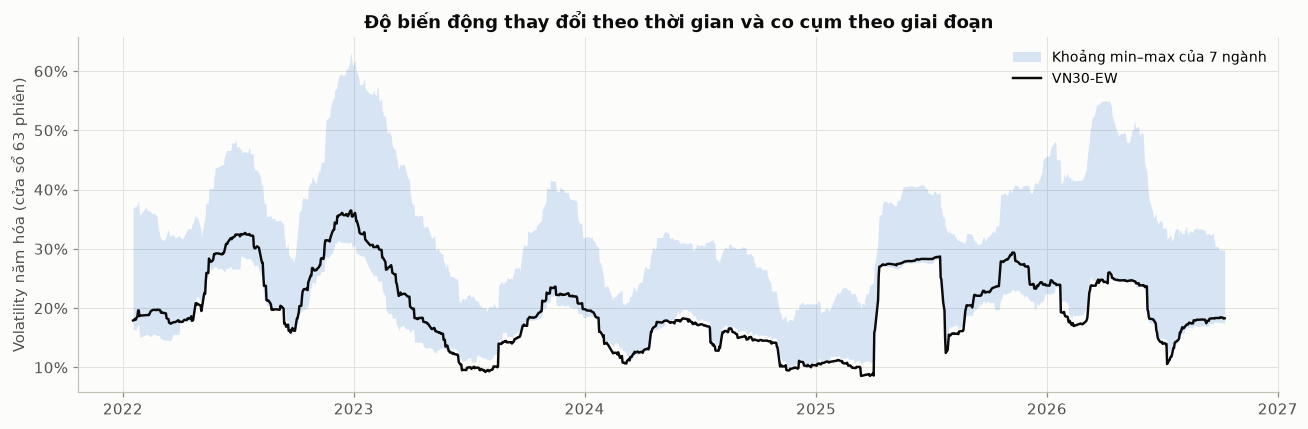

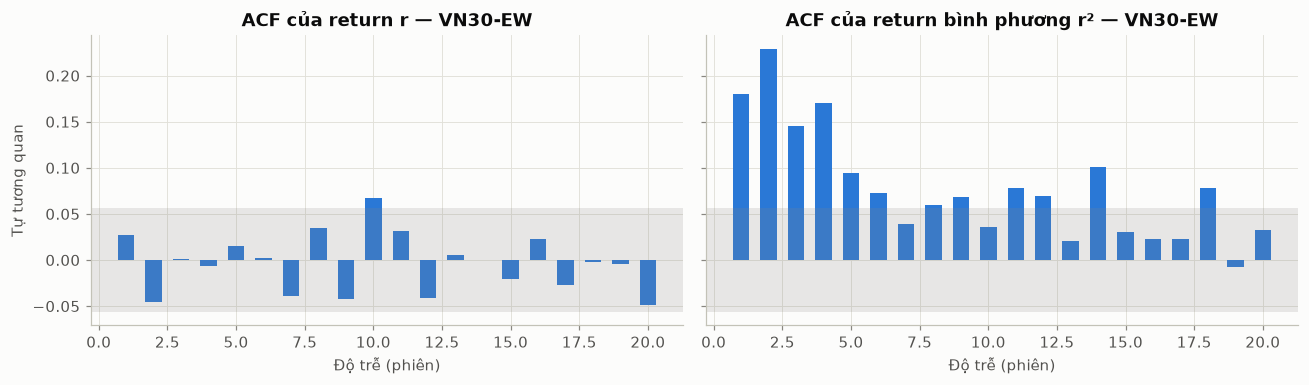

,LB Q(10) trên r,p-value (r),LB Q(10) trên r²,p-value (r²)
Ngân hàng,13.8462,0.1801,163.7716,0.0000
Bất động sản,11.8684,0.2940,202.8869,0.0000
Tiêu dùng & Bán lẻ,23.2987,0.0097,219.0489,0.0000
Năng lượng & Tiện ích,26.7877,0.0028,528.4222,0.0000
Thép & Vật liệu,20.1158,0.0282,290.3515,0.0000
Công nghệ,21.9907,0.0152,147.9287,0.0000
Dịch vụ tài chính,18.8642,0.0420,212.0782,0.0000
VN30-EW,14.6872,0.1439,193.8799,0.0000
1/N (7 ngành),18.2294,0.0512,224.8240,0.0000


In [15]:
win = 63
rv = assets.rolling(win).std() * np.sqrt(PPY)
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(rv.index, rv[SECTORS].min(axis=1), rv[SECTORS].max(axis=1), color=viz.CATEGORICAL[0], alpha=0.18,
                linewidth=0, label="Khoảng min–max của 7 ngành")
ax.plot(rv.index, rv["VN30-EW"], color=viz.INK, lw=1.6, label="VN30-EW")
viz.pct_axis(ax)
ax.set_ylabel("Volatility năm hóa (cửa sổ 63 phiên)")
ax.set_title("Độ biến động thay đổi theo thời gian và co cụm theo giai đoạn")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

def acf(x, nlags):
    x = np.asarray(x) - np.mean(x)
    d = x @ x
    return np.array([x[:-k] @ x[k:] / d for k in range(1, nlags + 1)])

def ljung_box(x, m):
    T = len(x); rho = acf(x, m)
    Q = T * (T + 2) * np.sum(rho ** 2 / (T - np.arange(1, m + 1)))
    return Q, stats.chi2.sf(Q, m)

lags = 20
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
band = 1.96 / np.sqrt(len(sec))
for ax, f, title in [(axes[0], lambda r: r, "ACF của return r"), (axes[1], lambda r: r ** 2, "ACF của return bình phương r²")]:
    a = acf(f(vn30ew.values), lags)
    ax.bar(range(1, lags + 1), a, color=viz.CATEGORICAL[0], width=0.6)
    ax.axhspan(-band, band, color=viz.MUTED, alpha=0.18, linewidth=0)
    ax.set_title(f"{title} — VN30-EW"); ax.set_xlabel("Độ trễ (phiên)")
axes[0].set_ylabel("Tự tương quan")
plt.tight_layout(); plt.show()

lb = pd.DataFrame({VI.get(c, c): {"LB Q(10) trên r": ljung_box(assets[c].values, 10)[0],
                                  "p-value (r)": ljung_box(assets[c].values, 10)[1],
                                  "LB Q(10) trên r²": ljung_box(assets[c].values ** 2, 10)[0],
                                  "p-value (r²)": ljung_box(assets[c].values ** 2, 10)[1]} for c in assets.columns}).T
display(viz.fmt(lb, dec=4))

- Return gần như **không tự tương quan** (khó dự báo hướng), nhưng **return bình phương tự tương quan mạnh** (Ljung-Box trên $r^2$ có p-value ≈ 0): giai đoạn biến động cao kéo theo biến động cao — hiệu ứng ARCH.
- Hệ quả cho thiết kế thực nghiệm: tham số ước lượng trên toàn mẫu **không ổn định theo thời gian** → so sánh mô hình phải dùng **backtest walk-forward (cửa sổ trượt, tái cân bằng định kỳ)**, và bootstrap phải là **block bootstrap** để giữ cấu trúc cụm biến động.

## 8. Cấu trúc tương quan

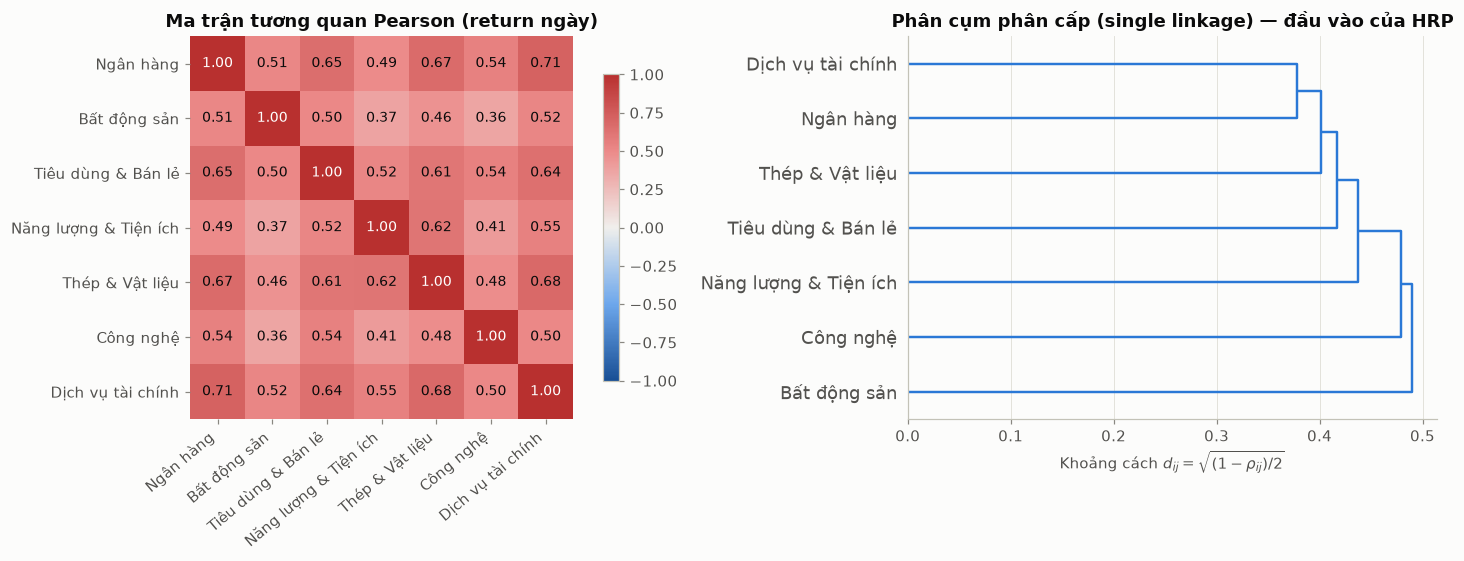

Tương quan giữa các ngành: min 0.36 | trung bình 0.54 | max 0.71


In [16]:
corr = sec.corr()
labels = [VI[s] for s in SECTORS]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
im = ax.imshow(corr.values, cmap=viz.DIVERGING, vmin=-1, vmax=1)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if corr.values[i, j] > 0.8 else viz.INK)
ax.set_xticks(range(7), labels, rotation=40, ha="right"); ax.set_yticks(range(7), labels)
ax.grid(False); ax.set_title("Ma trận tương quan Pearson (return ngày)")
for sp in ax.spines.values(): sp.set_visible(False)
plt.colorbar(im, ax=ax, shrink=0.8)

link = linkage(squareform(correlation_distance(corr.values), checks=False), method="single")
dendrogram(link, labels=labels, ax=axes[1], orientation="right", color_threshold=0,
           above_threshold_color=viz.CATEGORICAL[0])
axes[1].set_xlabel(r"Khoảng cách $d_{ij}=\sqrt{(1-\rho_{ij})/2}$")
axes[1].set_title("Phân cụm phân cấp (single linkage) — đầu vào của HRP")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

off = corr.values[np.triu_indices(7, 1)]
print(f"Tương quan giữa các ngành: min {off.min():.2f} | trung bình {off.mean():.2f} | max {off.max():.2f}")

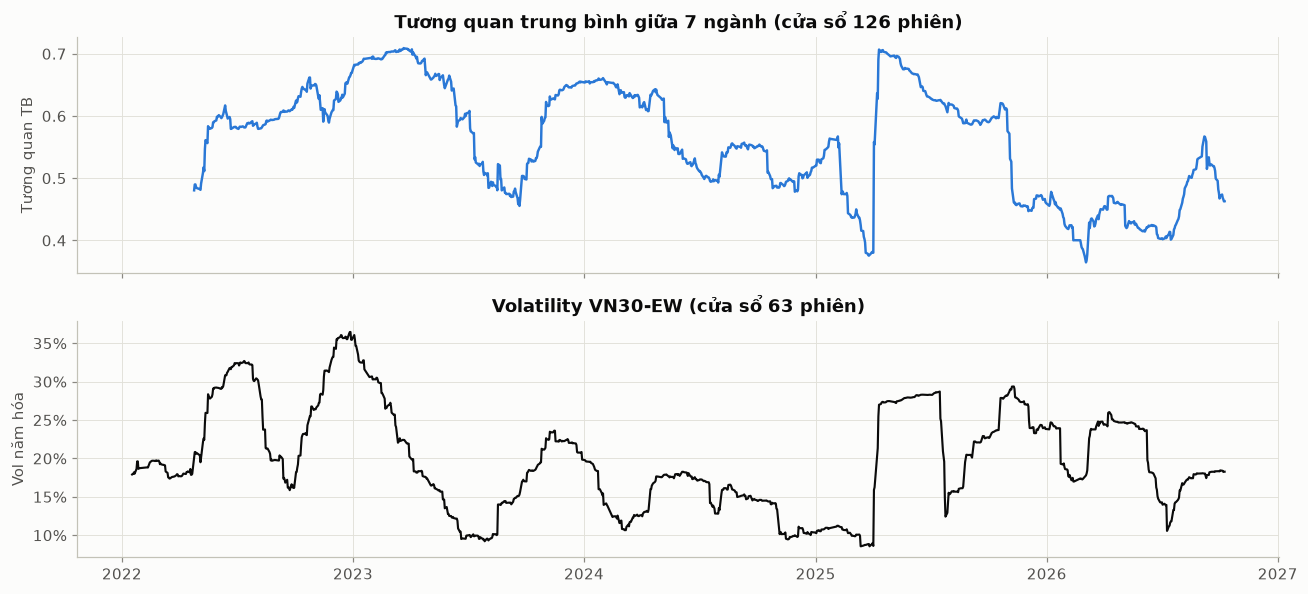

Hệ số tương quan giữa (tương quan TB trượt) và (volatility thị trường trượt, cùng cửa sổ 126): +0.44
Tương quan TB trượt: thấp nhất 0.36 (2026-03-04), cao nhất 0.71 (2023-03-22)


In [17]:
def avg_pairwise_corr(df):
    c = df.corr().values
    return c[np.triu_indices(len(c), 1)].mean()

roll_corr = pd.Series([avg_pairwise_corr(sec.iloc[i - 126:i]) for i in range(126, len(sec) + 1)],
                      index=sec.index[125:])
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(roll_corr.index, roll_corr, color=viz.CATEGORICAL[0], lw=1.6)
axes[0].set_ylabel("Tương quan TB"); axes[0].set_title("Tương quan trung bình giữa 7 ngành (cửa sổ 126 phiên)")
axes[1].plot(rv.index, rv["VN30-EW"], color=viz.INK, lw=1.4)
viz.pct_axis(axes[1]); axes[1].set_ylabel("Vol năm hóa")
axes[1].set_title("Volatility VN30-EW (cửa sổ 63 phiên)")
plt.tight_layout(); plt.show()

rv126 = (vn30ew.rolling(126).std() * np.sqrt(PPY)).reindex(roll_corr.index)
print(f"Hệ số tương quan giữa (tương quan TB trượt) và (volatility thị trường trượt, cùng cửa sổ 126): "
      f"{np.corrcoef(roll_corr, rv126)[0, 1]:+.2f}")
print(f"Tương quan TB trượt: thấp nhất {roll_corr.min():.2f} ({roll_corr.idxmin().date()}), "
      f"cao nhất {roll_corr.max():.2f} ({roll_corr.idxmax().date()})")

- Tương quan giữa các ngành **dương và cao** (khoảng 0.36 – 0.71). Cụm tài chính (Ngân hàng – Dịch vụ tài chính – Thép – Tiêu dùng) liên kết chặt; **Công nghệ (FPT)** và **Bất động sản** tách xa nhất → là các "nguồn đa dạng hóa" chính.
- Tương quan **không cố định**: dao động trong khoảng 0.36 – 0.71, đạt đỉnh ở giai đoạn cuối 2022 – đầu 2023 (đáy thị trường giá xuống) và ngay sau cú sốc thuế quan tháng 4/2025, đúng các giai đoạn biến động thị trường tăng vọt (tương quan giữa hai chuỗi trượt = +0.44). Đúng lúc nhà đầu tư cần đa dạng hóa nhất thì nó lại suy yếu. Vì vậy ma trận hiệp phương sai ước lượng trên quá khứ thường **đánh giá thấp rủi ro** trong khủng hoảng.
- Cấu trúc phân cấp rõ ràng của dendrogram là tiền đề tự nhiên cho **HRP**.

## 9. PCA & độ ổn định của ma trận hiệp phương sai

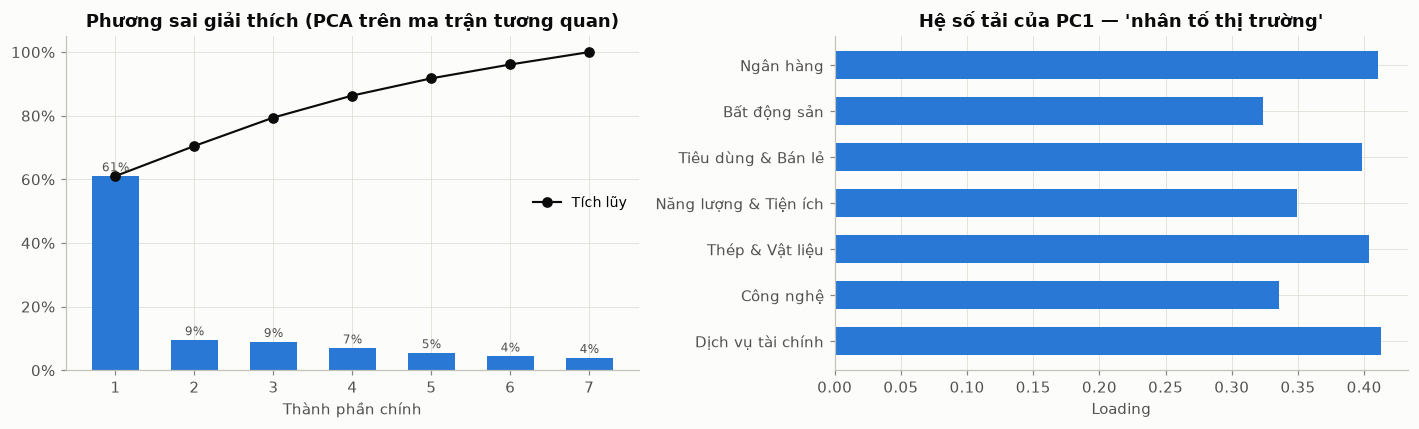

,N tài sản,Ước lượng,Số điều kiện κ(Σ),Hệ số co (shrinkage)
0,7,Mẫu (sample),19.885,
1,7,Ledoit-Wolf,18.995,0.010
2,30,Mẫu (sample),81.071,
3,30,Ledoit-Wolf,74.873,0.013


In [18]:
eigval, eigvec = np.linalg.eigh(corr.values)
order = eigval.argsort()[::-1]; eigval, eigvec = eigval[order], eigvec[:, order]
expl = eigval / eigval.sum()
pc1 = eigvec[:, 0] * np.sign(eigvec[:, 0].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, 8), expl, color=viz.CATEGORICAL[0], width=0.6)
axes[0].plot(range(1, 8), np.cumsum(expl), color=viz.INK, marker="o", lw=1.4, label="Tích lũy")
for i, e in enumerate(expl):
    axes[0].text(i + 1, e + 0.015, f"{e:.0%}", ha="center", fontsize=8, color=viz.INK2)
viz.pct_axis(axes[0]); axes[0].set_xlabel("Thành phần chính"); axes[0].set_title("Phương sai giải thích (PCA trên ma trận tương quan)")
axes[0].legend(loc="center right")
axes[1].barh(labels[::-1], pc1[::-1], color=viz.CATEGORICAL[0], height=0.6)
axes[1].set_title("Hệ số tải của PC1 — 'nhân tố thị trường'"); axes[1].set_xlabel("Loading")
plt.tight_layout(); plt.show()

def cond(m): return np.linalg.cond(m)
lw7 = LedoitWolf().fit(sec.values)
lw30 = LedoitWolf().fit(ret_clean.values)
cn = pd.DataFrame({
    "N tài sản": [7, 7, 30, 30],
    "Ước lượng": ["Mẫu (sample)", "Ledoit-Wolf", "Mẫu (sample)", "Ledoit-Wolf"],
    "Số điều kiện κ(Σ)": [cond(sec.cov().values), cond(lw7.covariance_), cond(ret_clean.cov().values), cond(lw30.covariance_)],
    "Hệ số co (shrinkage)": [np.nan, lw7.shrinkage_, np.nan, lw30.shrinkage_],
})
display(viz.fmt(cn, dec=3))

- **PC1 giải thích 61% phương sai** với hệ số tải cùng dấu cho mọi ngành: một nhân tố thị trường chung chi phối → giới hạn khả năng đa dạng hóa thuần cổ phiếu.
- Số điều kiện $\kappa(\Sigma)$ của ma trận 7×7 nhỏ hơn nhiều so với 30×30: việc gom ngành giúp $\Sigma^{-1}$ ổn định hơn, giảm khuếch đại sai số trong Markowitz, và giảm số chiều cho các thuật toán tiến hóa / Quality-Diversity. Hệ số co Ledoit-Wolf của bài toán 7 ngành nhỏ → ước lượng mẫu đã khá ổn định, nên notebook so sánh dùng ma trận hiệp phương sai mẫu.

## 10. Bản đồ rủi ro – lợi nhuận

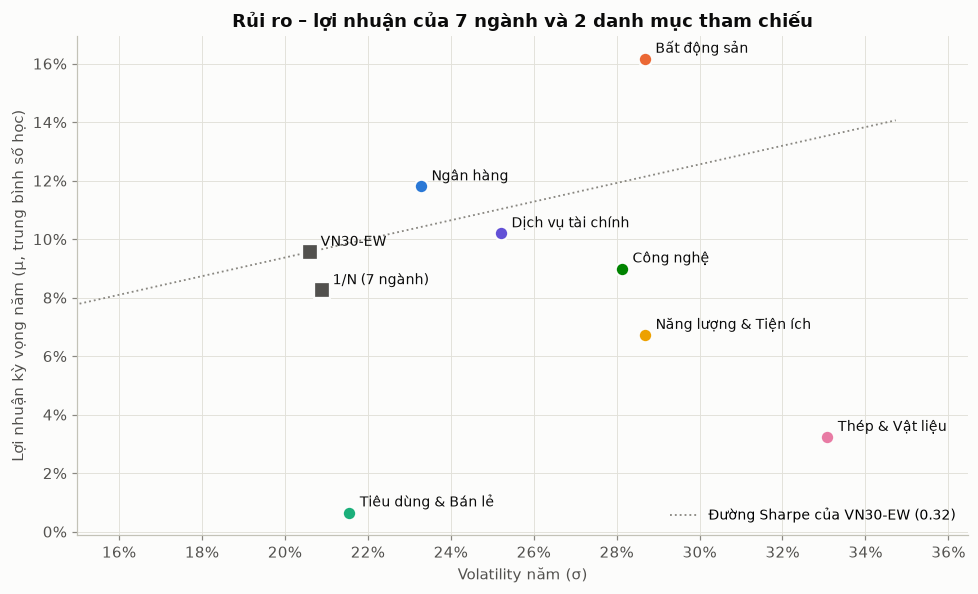

In [19]:
mu_a = assets.mean() * PPY
vol_a = assets.std() * np.sqrt(PPY)
fig, ax = plt.subplots(figsize=(9, 5.5))
for name in assets.columns:
    is_bench = name not in SECTORS
    ax.scatter(vol_a[name], mu_a[name], s=110 if is_bench else 80,
               color=viz.INK2 if is_bench else SEC_COLORS[name], marker="s" if is_bench else "o",
               edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(VI.get(name, name), (vol_a[name], mu_a[name]), xytext=(7, 4), textcoords="offset points", fontsize=9, color=viz.INK)
xs = np.linspace(0, vol_a.max() * 1.05, 10)
sr_mkt = (mu_a["VN30-EW"] - RF) / vol_a["VN30-EW"]
ax.plot(xs, RF + sr_mkt * xs, color=viz.MUTED, ls=":", lw=1.2, label=f"Đường Sharpe của VN30-EW ({sr_mkt:.2f})")
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y")
ax.xaxis.set_major_locator(plt.MultipleLocator(0.02))
ax.set_xlim(left=0.15); ax.set_xlabel("Volatility năm (σ)"); ax.set_ylabel("Lợi nhuận kỳ vọng năm (μ, trung bình số học)")
ax.set_title("Rủi ro – lợi nhuận của 7 ngành và 2 danh mục tham chiếu")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Hai danh mục chia đều (ô vuông) nằm **bên trái** hầu hết các ngành đơn lẻ với cùng mức lợi nhuận: lợi ích đa dạng hóa là có thật dù tương quan cao. Ngành **Bất động sản** có $\mu$ cao nhất nhưng cũng biến động mạnh và có drawdown sâu nhất.

## 11. Sai số ước lượng lợi nhuận kỳ vọng

Với $T$ năm dữ liệu, sai số chuẩn của lợi nhuận trung bình năm là $\sigma/\sqrt{T}$ — **không giảm khi lấy mẫu dày hơn** (ngày thay vì tháng), chỉ giảm khi có **thêm năm**.

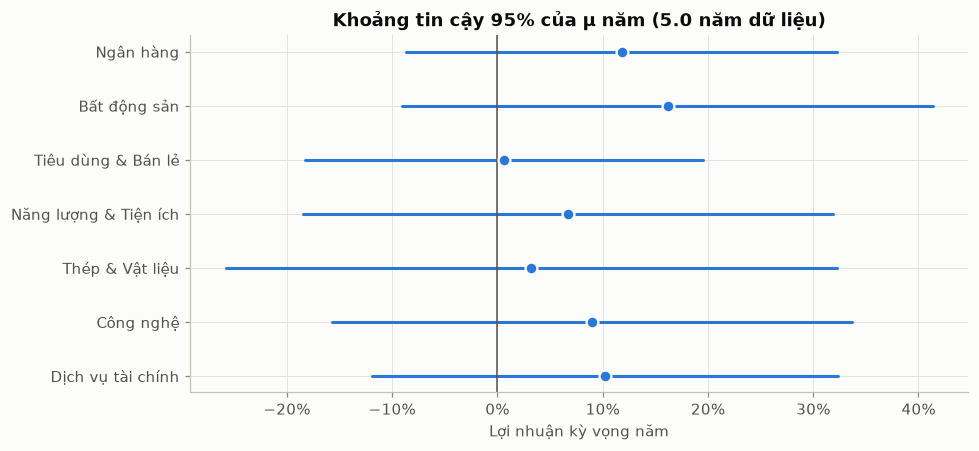

,μ nửa đầu,μ nửa sau,σ nửa đầu,σ nửa sau
Ngân hàng,10.54%,13.06%,25.05%,21.38%
Bất động sản,-4.76%,37.08%,25.76%,31.29%
Tiêu dùng & Bán lẻ,-6.63%,7.93%,22.37%,20.71%
Năng lượng & Tiện ích,-0.47%,13.91%,27.71%,29.65%
Thép & Vật liệu,0.28%,6.19%,36.51%,29.27%
Công nghệ,24.54%,-6.56%,25.83%,30.24%
Dịch vụ tài chính,0.69%,19.70%,25.41%,25.01%


Tương quan hạng Spearman giữa 2 nửa mẫu  —  μ: -0.39   |   σ: +0.64


In [20]:
years = len(sec) / PPY
se = vol_a[SECTORS] / np.sqrt(years)
ci = pd.DataFrame({"μ": mu_a[SECTORS], "lo": mu_a[SECTORS] - 1.96 * se, "hi": mu_a[SECTORS] + 1.96 * se}).rename(index=VI)

fig, ax = plt.subplots(figsize=(9, 4.2))
yy = np.arange(len(ci))[::-1]
for y, (name, r) in zip(yy, ci.iterrows()):
    ax.plot([r.lo, r.hi], [y, y], color=viz.CATEGORICAL[0], lw=2, solid_capstyle="round")
    ax.scatter(r["μ"], y, s=60, color=viz.CATEGORICAL[0], edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
ax.axvline(0, color=viz.INK2, lw=1)
ax.set_yticks(yy, ci.index); viz.pct_axis(ax, "x")
ax.set_title(f"Khoảng tin cậy 95% của μ năm ({years:.1f} năm dữ liệu)")
ax.set_xlabel("Lợi nhuận kỳ vọng năm")
plt.tight_layout(); plt.show()

half = len(sec) // 2
h1, h2 = sec.iloc[:half].mean() * PPY, sec.iloc[half:].mean() * PPY
s1, s2 = sec.iloc[:half].std() * np.sqrt(PPY), sec.iloc[half:].std() * np.sqrt(PPY)
stab = pd.DataFrame({"μ nửa đầu": h1, "μ nửa sau": h2, "σ nửa đầu": s1, "σ nửa sau": s2}).rename(index=VI)
display(viz.fmt(stab, pct=stab.columns))
print(f"Tương quan hạng Spearman giữa 2 nửa mẫu  —  μ: {stats.spearmanr(h1, h2)[0]:+.2f}   |   σ: {stats.spearmanr(s1, s2)[0]:+.2f}")

Khoảng tin cậy 95% của $\mu$ **rộng khoảng ±20–30 điểm % mỗi năm** và **tất cả đều chứa 0**: dữ liệu 5 năm không đủ để khẳng định ngành nào có lợi nhuận kỳ vọng cao hơn ngành nào. Thứ hạng $\mu$ giữa hai nửa mẫu thậm chí **tương quan âm** (Spearman −0.39; vd. Công nghệ +24.5% → −6.6%, Bất động sản −4.8% → +37.1%), trong khi thứ hạng $\sigma$ ổn định hơn nhiều (+0.64). Đây là lý do kinh điển khiến:
- **Markowitz** (đặc biệt Max Sharpe) là một "bộ khuếch đại sai số" (Michaud, 1989): dồn tỷ trọng vào ngành có $\hat\mu$ cao do may mắn.
- Các phương pháp **không dùng** $\mu$ (HRP, Min-Variance) hoặc **co** $\mu$ về một prior cân bằng (**Black-Litterman**) thường ổn định hơn ngoài mẫu.

## 12. Tổng kết EDA & hàm ý cho mô hình

| Phát hiện | Bằng chứng | Hàm ý cho bài toán tối ưu |
|---|---|---|
| Dữ liệu gốc có ngày nghỉ bị forward-fill và lỗi giá do chia tách/cổ tức | 87 phiên toàn 0; TCB −49.5%, VCB −33%, 3 cặp spike-reversal | Làm sạch trước khi ước lượng; năm hóa bằng ~242 phiên/năm |
| Phân phối đuôi dày, lệch trái | JB p ≈ 0; excess kurtosis 1.7–4.9; $\lvert z\rvert>3$ xảy ra ở 1.2–2.6% số phiên (chuẩn: 0.27%); CVaR thực cao hơn CVaR chuẩn 12–32% | Phương sai đánh giá thấp rủi ro đuôi → **Mean-CVaR** (LP) |
| Biến động co cụm, tham số thay đổi theo thời gian | Ljung-Box trên $r^2$ có p ≈ 0; rolling vol | Đánh giá bằng **walk-forward**, block bootstrap |
| Tương quan cao, có cấu trúc phân cấp, tăng khi thị trường biến động | ρ 0.36–0.71; dendrogram; tương quan trượt đạt đỉnh cuối 2022 và 4/2025 | **HRP** khai thác cấu trúc cây; giới hạn của đa dạng hóa |
| $\mu$ ước lượng rất nhiễu | CI 95% của cả 7 ngành chứa 0; Spearman thứ hạng $\mu$ giữa 2 nửa mẫu = −0.39 | Markowitz nhạy cảm → **Black-Litterman** (co về prior), so với **1/N** |
| Rủi ro thực tế (MDD, CVaR) không lồi / không khả vi theo $w$ | MDD phụ thuộc đường đi | **NSGA-III** tối ưu trực tiếp MDD như một mục tiêu; **MAP-Elites/CVT** cung cấp bản đồ các danh mục đa dạng |
| Số chiều nhỏ (N = 7), Σ điều kiện tốt | κ(Σ) = 20 (7 ngành) so với 81 (30 mã); PC1 giải thích 61% | Phù hợp cho thuật toán tiến hóa & Quality-Diversity |

→ Tiếp theo: **`02_So_sanh_mo_hinh.ipynb`** triển khai và so sánh 7 mô hình trên dữ liệu sạch.